# Practice Final Exam Solution
* Author: Kapil Kumar Sharma
* NetID: apl25002

In [24]:
version # make sure it says language R at the bottom!

               _                           
platform       x86_64-pc-linux-gnu         
arch           x86_64                      
os             linux-gnu                   
system         x86_64, linux-gnu           
status                                     
major          4                           
minor          6.1                         
year           2026                        
month          06                          
day            24                          
svn rev        90187                       
language       R                           
version.string R version 4.6.1 (2026-06-24)
nickname       Happy Hop                   

# Problem 1 (25 Points)

Suppose that in a random sample of 55 baseball pitchers, 8 are left handed.

a. Using the random sample, build a confidence interval for the proportion of left-handed baseball
pitchers with confidence level 90%.

In [25]:
# Given information
sample_size = 55
sample_success = 8
confidence = 0.90

# Calculate sample proportion
sample_proportion = sample_success / sample_size

# Calculate alpha
alpha = 1 - confidence

# Calculate critical Z-value
z_value = qnorm(1 - alpha/2)

# Calculate standard error
SE = sqrt(sample_proportion * (1-sample_proportion) / sample_size)

# Calculate margin of error
ME = z_value * SE

# Calculate confidence interval
lower = sample_proportion - ME
upper = sample_proportion + ME

# Print results
cat("Sample proportion =", sample_proportion, "\n")
cat("Critical Z-value =", z_value, "\n")
cat("Standard error =", SE, "\n")
cat("Margin of error =", ME, "\n")
cat("Lower limit =", lower, "\n")
cat("Upper limit =", upper, "\n")

Sample proportion = 0.1454545 
Critical Z-value = 1.644854 
Standard error = 0.04753898 
Margin of error = 0.07819467 
Lower limit = 0.06725988 
Upper limit = 0.2236492 


Final answer: The 90% confidence interval is approximately (0.0673, 0.2236), or 6.73% to 22.36%.

b. Suppose you know for sure that no less than 70% of baseball pitchers are right handed
(assume that each baseball pitcher is either left handed or right handed). You want to
sample additional players so that the width of the confidence interval at a 95% confidence
level is no larger than 0.03. How many additional baseball pitchers should you sample?

In [26]:
# Given information
sample_size = 55
confidence = 0.95
p = 0.30 #no less than 70% of baseball pitchers
q = 1-p
CI_width = 0.03

# Calculate alpha and critical Z-value
alpha = 1-confidence
z_value = qnorm(1-alpha/2)

# Margin of error
E = CI_width/2

# Calculate required total sample size
required_sample_size = (z_value^2 * p * q) / (E^2)

# Calculate additional sample size
additional_sample_size = required_sample_size-sample_size

cat("Critical Z-value =", z_value, "\n")
cat("Margin of error =", E, "\n")
cat("Required total sample size =", required_sample_size, "\n")
cat("Additional sample size =", additional_sample_size, "\n")

Critical Z-value = 1.959964 
Margin of error = 0.015 
Required total sample size = 3585.362 
Additional sample size = 3530.362 


Final answer: 3,531 additional pitchers.

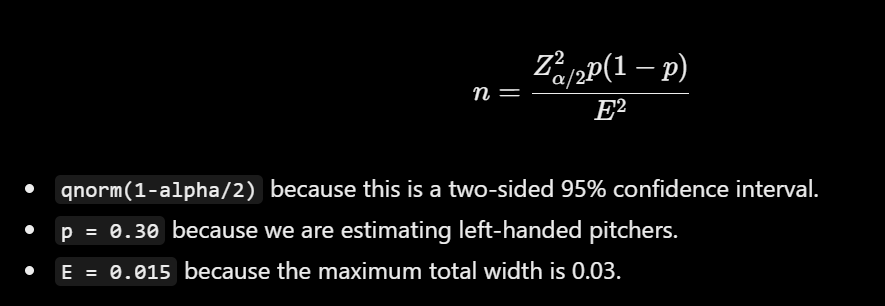

# Problem 2 (30 Points)

Consider the Cars93 data frame in the MASS library in R.


a. Build a simple linear regression model for MPG.highway using MGP.city. Save the regression
in a variable called car reg. Print out the regression results.

In [27]:
# Load MASS library
library(MASS)

# Load Cars93 dataset
data(Cars93)

# Build simple linear regression model
car_reg = lm(MPG.highway ~ MPG.city, data = Cars93)

# Print regression results
summary(car_reg)


Call:
lm(formula = MPG.highway ~ MPG.city, data = Cars93)

Residuals:
    Min      1Q  Median      3Q     Max 
-3.8185 -1.1764  0.1369  1.3458  4.5547 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  9.05658    0.75691   11.96   <2e-16 ***
MPG.city     0.89555    0.03283   27.28   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Residual standard error: 1.77 on 91 degrees of freedom
Multiple R-squared:  0.891,	Adjusted R-squared:  0.8898 
F-statistic:   744 on 1 and 91 DF,  p-value: < 2.2e-16


The model:
- Dependent variable (Y): MPG.highway
- Independent variable (X): MPG.city
- Model: **MPG.highway = b0 + b1(MPG.city)**


Predicted_MPG_highway = 9.05658 + 0.89555 * MPG_city

From Output:
1. Intercept: Estimated highway MPG when city MPG is zero.
2. MPG.city coefficient: Expected change in highway MPG for each one-unit increase in city MPG.
3. R-squared: Percentage of variation in highway MPG explained by city MPG.
4. p-value: Used to assess whether the regression coefficients are statistically significant.

b. Are both coefficients significant at the 95% confidence level?

Both the intercept and MPG.city coefficients are statistically significant at the 95% confidence level because their p-values are less than 0.05. Therefore, MPG.city is a significant predictor of MPG.highway.

In [6]:
summary_result = summary(car_reg)$coefficients

summary_result[, "Pr(>|t|)"] < 0.05

(Intercept)    MPG.city 
       TRUE        TRUE

c. What is the R-squared and what is the adjusted R-squared? Explain the di↵erence between
the two.

From regression output:
- R-squared = 0.891 (89.1%)
- Adjusted R-squared = 0.8898 (88.98%)


Difference between R-squared and Adjusted R-squared
- R-squared: Measures the proportion of variation in the dependent variable (MPG.highway) explained by the independent variable (MPG.city). Here, MPG.city explains 89.1% of the variation in highway mileage.
- Adjusted R-squared: Measures the same explanatory power but adjusts for the number of independent variables and the sample size. It penalizes adding variables that do not meaningfully improve the model.

d. Using the R-squared, write code to calculate the adjusted R-squared, and cross check to
ensure it equates to what is reported.

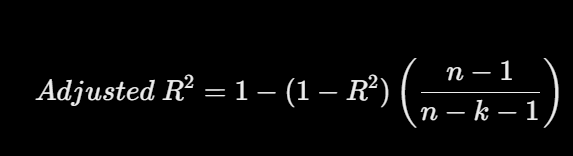

In [8]:
# Given values
R_squared = summary(car_reg)$r.squared #0.891
n = 93
k = 1

# Calculate Adjusted R-squared
Adjusted_R_squared = 1 - (1-R_squared)*((n-1)/(n-k-1))

# Print results
cat("Calculated Adjusted R-squared =", Adjusted_R_squared, "\n")

# Cross-check with regression output
cat("Reported Adjusted R-squared =", summary(car_reg)$adj.r.squared, "\n")

Calculated Adjusted R-squared = 0.8898171 
Reported Adjusted R-squared = 0.8898171 


The adjusted R-squared formula is correctly applied, and the result has been successfully cross-checked against the regression model output.

e. Calculate the SSR, SST, and SSE, and explain each in the context of this problem.

In [9]:
# Actual values of MPG.highway
Y = Cars93$MPG.highway

# Predicted values from regression model
Y_hat = fitted(car_reg)

# Mean of actual MPG.highway
Y_bar = mean(Y)

# Calculate SSR
SSR = sum((Y_hat - Y_bar)^2)

# Calculate SST
SST = sum((Y - Y_bar)^2)

# Calculate SSE
SSE = sum((Y - Y_hat)^2)

# Print results
cat("SSR =", SSR, "\n")
cat("SST =", SST, "\n")
cat("SSE =", SSE, "\n")

# Verify the relationship
cat("SSR + SSE =", SSR + SSE, "\n")
cat("SST =", SST, "\n")

SSR = 2330.281 
SST = 2615.312 
SSE = 285.0303 
SSR + SSE = 2615.312 
SST = 2615.312 


**R-Square = R^2 = SSR / SST**

SSR: Represents the variation in highway MPG explained by the relationship with city MPG. A higher SSR relative to SST indicates that the model explains more of the variation.



SST: Represents the total variation in highway MPG across all 93 cars, before considering the regression model.



SSE: Represents the remaining variation in highway MPG that the model cannot explain. These are the prediction errors (residuals).

f. What is the expected MPG.highway for a vehicle with MGP.city = 16?

In [10]:
# Given MPG.city
MPG_city = 16

# Calculate predicted MPG.highway
predicted_MPG_highway = 9.05658 + 0.89555 * MPG_city

cat("Expected MPG.highway =", predicted_MPG_highway, "\n")

Expected MPG.highway = 23.38538 


The expected highway mileage for a vehicle with city mileage of 16 MPG is approximately 23.39 MPG, based on the fitted regression model.

g. Construct a confidence interval for the expected value of MPG.highway for vehicles with
MGP.city = 16 at the 95% confidence level.

In [11]:
# Create new observation
new_data = data.frame(MPG.city = 16)

# Calculate 95% confidence interval
confidence_interval = predict(
  car_reg,
  newdata = new_data,
  interval = "confidence",
  level = 0.95
)

# Print results
cat("Expected MPG.highway and 95% Confidence Interval:\n")
print(confidence_interval)

Expected MPG.highway and 95% Confidence Interval:
       fit      lwr      upr
1 23.38533 22.83285 23.93782


For vehicles with MPG.city = 16, the estimated expected MPG.highway is 23.385 MPG. The 95% confidence interval is (22.83285, 23.93782). This means we are 95% confident that the population mean highway mileage for vehicles with a city mileage of 16 MPG falls within this interval.

h. Construct a data frame with a single column called MPG.city populated with values 8, 10,
12, 14. Build prediction intervals for cars with these MPG.city using the predict function in
R.

In [12]:
# Create a data frame with MPG.city values
new_data = data.frame(MPG.city = c(8, 10, 12, 14))

# Build 95% prediction intervals
prediction_intervals = predict(
  car_reg,
  newdata = new_data,
  interval = "prediction",
  level = 0.95
)

# Print prediction intervals
cat("95% Prediction Intervals:\n")
print(prediction_intervals)

95% Prediction Intervals:
       fit      lwr      upr
1 16.22095 12.56454 19.87737
2 18.01205 14.38686 21.63724
3 19.80314 16.20473 23.40156
4 21.59424 18.01803 25.17045


The prediction intervals estimate the range of highway mileage for individual cars at each specified city MPG, with 95% confidence. These intervals are wider than confidence intervals for the expected value because they account for individual vehicle variation as well as uncertainty in the estimated regression line.

# Problem 3 (15 Points)

To compare the wearing of two types of automobile engines, 1 and 2, an experimenter chose to “pair”
the measurements, comparing the wear for the two types of engines on each of 7 automobiles, as
shown below.

Determine whether these data are sufficient to infer at the 10% significance level that the two
types of engines wear di↵erently. Specify the hypotheses clearly, report the p-value, and state the
conclusion.
5



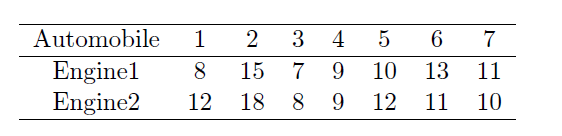

Let \(d = Engine1 - Engine2\).
- Null hypothesis (H₀): \(mu_d = 0) — there is no difference in average wear between the two engine types.
- Alternative hypothesis (H₁): \(mu_d != 0) — the two engine types have different average wear.

In [13]:
# Engine wear measurements
sample_1 = c(8, 15, 7, 9, 10, 13, 11)
sample_2 = c(12, 18, 8, 9, 12, 11, 10)

# Calculate paired differences
difference = sample_1 - sample_2

# Calculate sample statistics
n_diff = length(difference)
diff_bar = mean(difference)
sd_diff = sd(difference)

# Significance level
alpha = 0.10

# Degrees of freedom
df = n_diff - 1

# Critical t-value (two-tailed)
Critical_value = qt(1-alpha/2, df)

# Calculate t-statistic
t_two_sample = diff_bar/(sd_diff/sqrt(n_diff))

# Calculate two-tailed p-value
p_value = 2*pt(-abs(t_two_sample), df)

# Print results
cat("Mean difference =", diff_bar, "\n")
cat("Standard deviation =", sd_diff, "\n")
cat("Degrees of freedom =", df, "\n")
cat("Critical t-value =", Critical_value, "\n")
cat("t-statistic =", t_two_sample, "\n")
cat("p-value =", p_value, "\n")

Mean difference = -1 
Standard deviation = 2.160247 
Degrees of freedom = 6 
Critical t-value = 1.94318 
t-statistic = -1.224745 
p-value = 0.2665697 


Since:
\[
p-value=0.2665697 > alpha=0.10
\]

We fail to reject the null hypothesis.


Conclusion:

At the 10% significance level, there is insufficient statistical evidence to conclude that the two types of automobile engines have different average wear. Although the average paired difference is -1, this difference is not statistically significant (p-value = 0.2666).

# Problem 4 (30 points)


Dillow is a home and neighborhood site for buyers and renters. A linear regression model was built
for estimating the price of houses in a city using as predictors the square feet of the house, whether
or not the house has a pool, and the crime index in the neighborhood of the house, which is on a
scale of 1-10, 1 being the least crime and 10 being the most crime. Answer the following questions
based on the regression output above, which has some missing values. Show all steps.

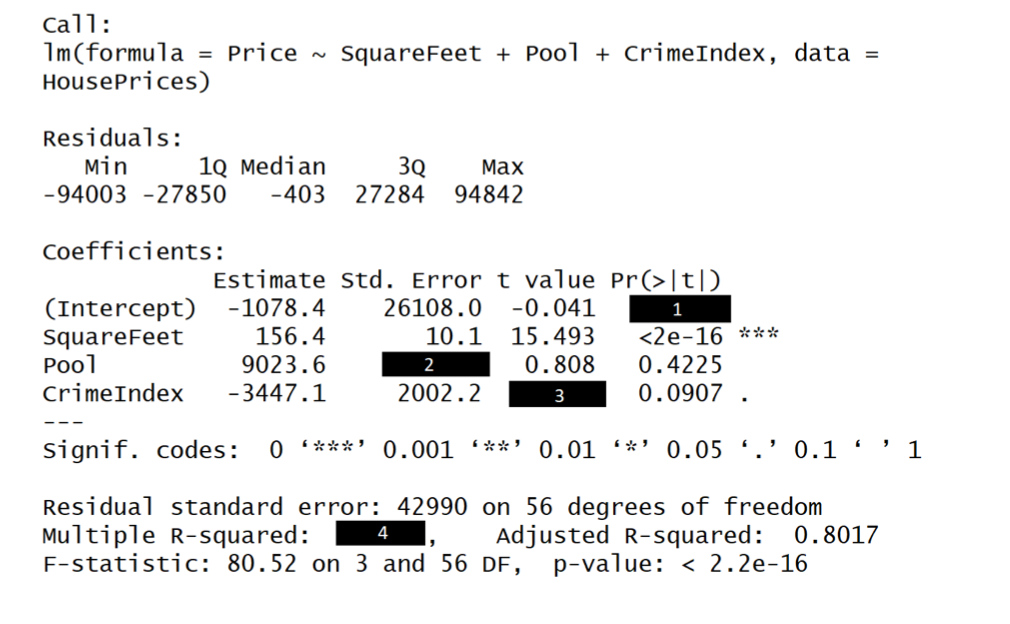

a. How many houses are used to build the regression model?

The regression model uses 3 independent variables and has 56 residual degrees of freedom. Using the formula \(df=n-k-1\), the total number of houses used to build the regression model is \(56+3+1=60\).

b. Calculated the values behind box 1, box 2, box 3, and box 4.

In [14]:
p_value_1 = 2 * pt(-abs(-0.041), df = 56)
cat("Box 1 =", p_value_1)

Box 1 = 0.9674417

In [16]:
estimate_pool = 9023.6
t_value_pool = 0.808

SE_Pool = estimate_pool / t_value_pool
cat("Box 2 =", SE_Pool)

Box 2 = 11167.82

In [17]:
estimate_crimeIndex = -3447.1
standardError_crimeIndex = 2002.2

t_CrimeIndex = estimate_crimeIndex / standardError_crimeIndex
cat("Box 3 =", t_CrimeIndex)

Box 3 = -1.721656

In [18]:
Adjusted_R_squared = 0.8017
n = 60
k = 3

R_squared = 1 - (1-Adjusted_R_squared)*((n-k-1)/(n-1))

cat("Box 4 =", R_squared)

Box 4 = 0.8117831

c. Conduct a hypothesis test to determine if there is a statistically significant relationship between
the predictors and house price. Specify the hypotheses clearly, report the p-value and test statistics, and determine the outcome of the test at the 95% confidence level.

In [22]:
# Values from regression output
F_value = 80.52     #F-statistic
df1 = 3
df2 = 56
alpha = 0.05        #95% confidence level

# Calculate p-value
p_value = pf(F_value, df1, df2, lower.tail = FALSE)

# Calculate critical F-value
Critical_value = qf(1-alpha, df1, df2)

# Print results
cat("F-statistic =", F_value, "\n")
cat("Numerator degrees of freedom =", df1, "\n")
cat("Denominator degrees of freedom =", df2, "\n")
cat("Critical F-value =", Critical_value, "\n")
cat("p-value =", p_value, "\n")

# Decision
if (p_value < alpha) {
  cat("Reject H0: The overall regression model is statistically significant.\n")
} else {
  cat("Fail to reject H0: The overall regression model is not statistically significant.\n")
}

F-statistic = 80.52 
Numerator degrees of freedom = 3 
Denominator degrees of freedom = 56 
Critical F-value = 2.769431 
p-value = 2.675535e-20 
Reject H0: The overall regression model is statistically significant.


Decision
Both conditions lead to rejecting the null hypothesis:
1. F-statistic (80.52) > Critical F-value (2.769431).
2. p-value (2.675535 × 10⁻²⁰) < 0.05.

Reject H₀

Conclusion:
At the 95% confidence level, the overall regression model is statistically significant (F(3, 56) = 80.52, p = 2.675535 × 10⁻²⁰). Therefore, we reject the null hypothesis and conclude that there is sufficient statistical evidence that at least one of the predictors (SquareFeet, Pool, or CrimeIndex) has a statistically significant linear relationship with house price.

d. Suppose a house with a pool is predicted to have price $378, 000 based on the regression
model. What is the predicted value of a house with 100 fewer square feet, no pool, and the
same crime index?

In [23]:
# Original predicted house price
original_price = 378000

# Regression coefficients
squarefeet_coef = 156.4
pool_coef = 9023.6

# Changes
change_squarefeet = -100
change_pool = -1

# Calculate new predicted price
new_price = original_price +
  (change_squarefeet * squarefeet_coef) +
  (change_pool * pool_coef)

cat("New predicted house price = $", new_price, "\n")

New predicted house price = $ 353336.4 


The predicted price of the new house is $353,336.40.

The price decreases by 15640 due to 100 fewer square feet and by $9,023.60 due to the absence of a pool. Since the crime index remains unchanged, it has no impact on the price difference.